Dataset       Model  Val_PR_AUC  Test_PR_AUC  Recall20_Prob  Recall20_Density  Test_Precision  Test_Recall  Test_F1
    JM1 Baseline_LR      0.3783       0.3830         0.1164            0.3552          0.5741       0.0925   0.1594
    JM1 Baseline_RF      0.4243       0.3657         0.1552            0.3463          0.4919       0.1821   0.2658
    JM1 Weighted_LR      0.3758       0.3841         0.1104            0.3582          0.3453       0.5164   0.4139
    JM1 Weighted_RF      0.4270       0.3674         0.1522            0.3701          0.4223       0.3731   0.3962
    PC4 Baseline_LR      0.6151       0.6663         0.3889            0.5833          0.6154       0.4444   0.5161
    PC4 Baseline_RF      0.6569       0.6899         0.4167            0.5833          0.8125       0.3611   0.5000
    PC4 Weighted_LR      0.6249       0.6414         0.3611            0.5278          0.3947       0.8333   0.5357
    PC4 Weighted_RF      0.6600       0.6906         0.5000            0

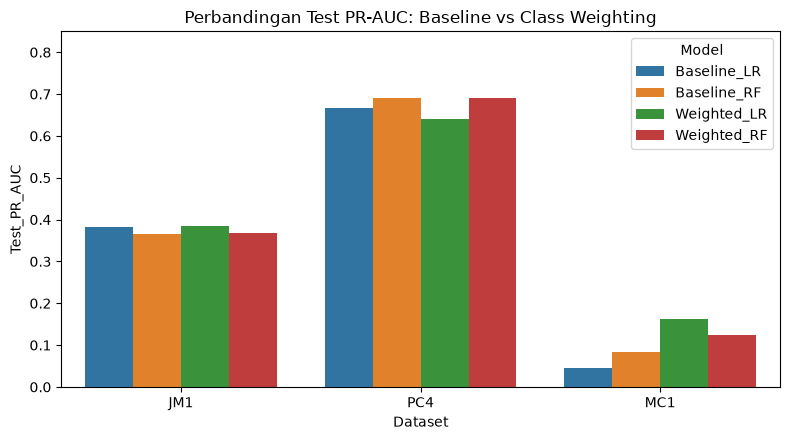

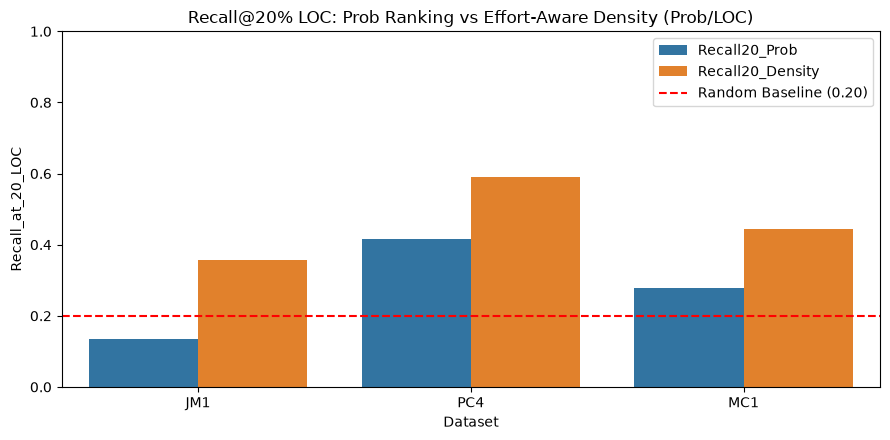

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.io import arff
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, precision_score, recall_score, f1_score

def load_nasa_arff(filepath):
    data, _ = arff.loadarff(filepath)
    df = pd.DataFrame(data)
    target_col = df.columns[-1]
    y = df[target_col].apply(lambda x: 1 if (x.decode("utf-8") if isinstance(x, bytes) else x) == "Y" else 0)
    X = df.drop(columns=[target_col]).apply(pd.to_numeric)
    return X, y

def recall_at_20_loc(y_true, scores, loc_values, budget_ratio=0.20):
    eval_df = pd.DataFrame({"y": y_true.values, "score": scores, "loc": loc_values.values})
    eval_df = eval_df.sort_values(by="score", ascending=False).reset_index(drop=True)
    eval_df["cum_loc"] = eval_df["loc"].cumsum()
    
    budget_loc = eval_df["loc"].sum() * budget_ratio
    inspected = eval_df[eval_df["cum_loc"] <= budget_loc]
    
    total_defects = eval_df["y"].sum()
    return inspected["y"].sum() / total_defects if total_defects > 0 else 0.0

data_dir = Path("../data")
datasets = ["JM1.arff", "PC4.arff", "MC1.arff"]
all_results = []

for fname in datasets:
    X, y = load_nasa_arff(data_dir / fname)
    
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.40, stratify=y, random_state=42
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
    )
    
    models = {
        "Baseline_LR": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=1000, random_state=42))
        ]),
        "Baseline_RF": RandomForestClassifier(n_estimators=100, random_state=42),
        "Weighted_LR": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
        ]),
        "Weighted_RF": RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42),
    }
    
    loc_test = X_test["LOC_TOTAL"].replace(0, 1)  # hindari pembagian dengan 0
    
    for name, model in models.items():
        model.fit(X_train, y_train)
        
        val_prob = model.predict_proba(X_val)[:, 1]
        test_prob = model.predict_proba(X_test)[:, 1]
        test_pred = model.predict(X_test)
        
        # Skenario B: Ranking berdasarkan Probabilitas (PofB20)
        rec20_prob = recall_at_20_loc(y_test, test_prob, X_test["LOC_TOTAL"])
        # Skenario C: Effort-Aware Ranking berdasarkan Prob/LOC (NPofB20)
        rec20_density = recall_at_20_loc(y_test, test_prob / loc_test, X_test["LOC_TOTAL"])
        
        all_results.append({
            "Dataset": fname.replace(".arff", ""),
            "Model": name,
            "Val_PR_AUC": round(average_precision_score(y_val, val_prob), 4),
            "Test_PR_AUC": round(average_precision_score(y_test, test_prob), 4),
            "Recall20_Prob": round(rec20_prob, 4),
            "Recall20_Density": round(rec20_density, 4),
            "Test_Precision": round(precision_score(y_test, test_pred, zero_division=0), 4),
            "Test_Recall": round(recall_score(y_test, test_pred, zero_division=0), 4),
            "Test_F1": round(f1_score(y_test, test_pred, zero_division=0), 4)
        })

df_res = pd.DataFrame(all_results)
df_res.to_csv("../results/metrics.csv", index=False)
print(df_res.to_string(index=False))

# --- GRAFIK 1: Perbandingan Test PR-AUC ---
plt.figure(figsize=(8, 4.5))
sns.barplot(data=df_res, x="Dataset", y="Test_PR_AUC", hue="Model")
plt.title("Perbandingan Test PR-AUC: Baseline vs Class Weighting")
plt.ylim(0, 0.85)
plt.tight_layout()
plt.savefig("../figures/pr_auc_comparison.png", dpi=300)
plt.show()

# --- GRAFIK 2: Perbandingan Recall@20% LOC (Prob vs Prob/LOC) ---
df_melt = df_res.melt(
    id_vars=["Dataset", "Model"],
    value_vars=["Recall20_Prob", "Recall20_Density"],
    var_name="Ranking_Strategy",
    value_name="Recall_at_20_LOC"
)
plt.figure(figsize=(9, 4.5))
sns.barplot(data=df_melt, x="Dataset", y="Recall_at_20_LOC", hue="Ranking_Strategy", errorbar=None)
plt.axhline(0.20, color="red", linestyle="--", label="Random Baseline (0.20)")
plt.title("Recall@20% LOC: Prob Ranking vs Effort-Aware Density (Prob/LOC)")
plt.ylim(0, 1.0)
plt.legend()
plt.tight_layout()
plt.savefig("../figures/recall20_loc_comparison.png", dpi=300)
plt.show()